# DTU dataset, mild reverberation: overt and masked onsets, intensity-level control

The overt/masked analysis of this project's `diotic_overt_masked_onsets.ipynb`, cell for cell, on an independent two-talker EEG dataset: Fuglsang, Dau & Hjortkjaer 2017, NeuroImage 156:435-444 (Zenodo 1199011; 18 subjects, 64-channel EEG, two talkers at +-60 degrees, attend one). The main forward models of these trials are in `dtu_mild.ipynb`.

**How the data were prepared** (`dtu/dtu_pipeline.py`, on the cluster; run from `dtu.ipynb`), aligned with this project step for step:
- EEG and trials as `dtu_mild.ipynb`: the 20 two-talker trials in this room; the single-talker trials are not analysed
- Overt and masked onsets as `predictors/brodbeck2020_predictors.py` (recipe `log`, this project's `SPLIT_RECIPE`): each talker's onsets split at full resolution (128 bands, before binning into 8) into the part still in the mixture's onsets (overt = min(talker, mixture)) and the part the other talker covers (masked = max(talker - mixture, 0)), so overt + masked = the talker's onsets
- Intensity tiers for the level-aware control: the mixture's onsets split into low, mid and high by the tertiles of each onset's summed intensity, per band, pooled over every mixture
- The mixture is the two talkers summed at the levels they were played at, so the onsets "at their level in the mixture" are the onsets of the main models; the rooms were simulated at presentation, so the split does not include the rooms' reverberation
- TRFs and tests as this project's overt/masked notebooks

**ROI:** this project's clean-speech ROI (`roi.txt`, from the cocktail clean-speech whole-scalp tests). Every model test below runs within it (one-tailed TFCE in the ROI, and the ROI-averaged t-test), and every response function is averaged over it.

**Results come from the cluster**: run `dtu_run()` in `dtu.ipynb` first; this notebook only reads them.

In [1]:
# Reloads the code every time it runs, so changes pulled from GitHub take effect without
# restarting the kernel (Run All is enough).
import importlib, sys
for _module in ('experiment', 'parameters'):
    if getattr(sys.modules.get(_module), '__spec__', None):
        importlib.reload(sys.modules[_module])
from parameters import *

## DTU mild (overt onsets)

In [2]:
# Reads these results from the cluster and sets the ROI: this project's clean-speech ROI (roi.txt),
# found from the cocktail clean-speech whole-scalp tests. Every test below runs within it.
ROI = dtu_setup('mild', 'overt-masked')

DTU mild: 18 subjects, 20 trials of 50 s each.
ROI, this project's clean-speech ROI (18 sensors): AF3, F1, F3, F5, F7, FC5, FC3, C1, C3, C5, AF4, AFz, F6, FT8, FC6, FC4, FC2, C2
Every model test within the ROI above; ROI means and TRFs in the same ROI.


<small>

**Brodbeck et al. 2020: Two talkers, overt/masked split vs plain onsets**

- Splitting onsets into overt and masked improves the fit: t_max = 6.81, p < 0.001
- About 67% of onset magnitude is overt, 33% masked

</small>

/Users/joshuaighalo/Github Repositories/cocktail-cortical/analysis/experiment.py:1063: UserWarning: Warning: converting a masked element to nan.
  mean_value = float(data.mean())


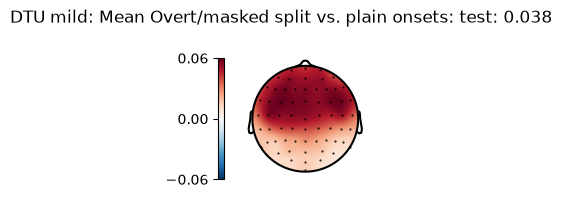

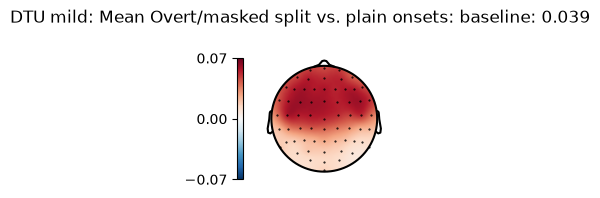

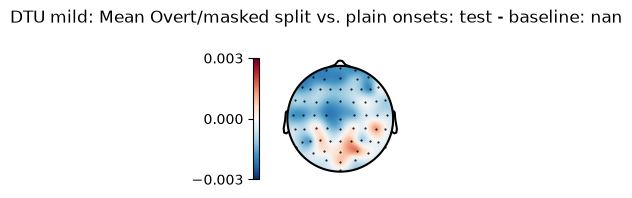

In [3]:
# Overt/masked split vs. plain onsets (DTU mild)
# overt/masked = the split of each speaker's onsets into the part still visible in the mixture and
# the part the other speaker covers, with the speaker at its level in the mixture.
# Brodbeck et al. 2020 ran this comparison too: splitting onsets into overt/masked significantly improved the model overall, t = 6.81, p < .001.

# FULL_INMIX  = Eatt + Oatt + Eign + Oign + Emix + Omix   (Oatt, Oign at their level in the mixture)
# FULL_MASKED = Eatt + Oatt_overt + Oatt_masked + Eign + Oign_overt + Oign_masked + Emix + Omix
#
# Comparison: FULL_MASKED > FULL_INMIX
#   (does splitting Oatt/Oign into overt + masked improve the fit? overt + masked == Oatt/Oign,
#   so the two models carry the same onsets, only split or not)
#
# Full predictor names: print(FULL_MASKED) and print(FULL_INMIX); <recipe> is SPLIT_RECIPE
# (parameters.py), e.g. gammatone-<recipe>-on-overt-8 for the attended overt onsets.

data, diff, result = dtu_model_test('Overt/masked split vs. plain onsets', 'mild', 'overt-masked')
show_topomap_trio(data, diff, result, 'Overt/masked split vs. plain onsets', 'DTU mild', None)

In [4]:
display(result)
print(f"Overt/masked split vs. plain onsets (DTU mild): TFCE {tfce_summary(result)}")
ttest = test.TTestOneSample(f'roi_{METRIC}', data=diff, tail=1)
print(f"Overt/masked split vs. plain onsets (DTU mild): ROI model comparison t({ttest.df}) = {ttest.t:.3f}, p = {ttest.p:.4f}")

<TTestRelated 'r', 'model', 'test', 'baseline', 'subject' (n=18), tail=1, samples=10000, tfce=True, p = 1.000>

Overt/masked split vs. plain onsets (DTU mild): TFCE t_max = 0.02, p = 1.000
Overt/masked split vs. plain onsets (DTU mild): ROI model comparison t(17) = -3.168, p = 0.9972


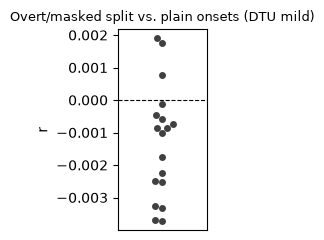

In [5]:
p = show_subject_swarm(diff, 'Overt/masked split vs. plain onsets', 'DTU mild')

In [6]:
# Loaded once here, reused by every STRF/peak/waveform/attention-
# effect/masking-comparison cell in both this subsection and "masked
# onset" below - same reasoning as data_full above, for FULL_MASKED.
data_masked = dtu_trfs('mild', 'overt-masked')

<small>

**Brodbeck et al. 2020: Two talkers, overt onset attend unique contribution**

- Overt attended onsets: t_max = 3.34, p = 0.027 (weaker than masked)

</small>

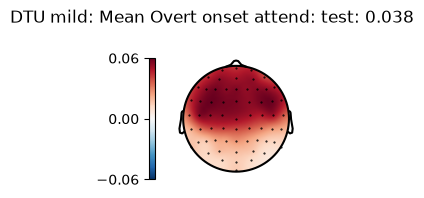

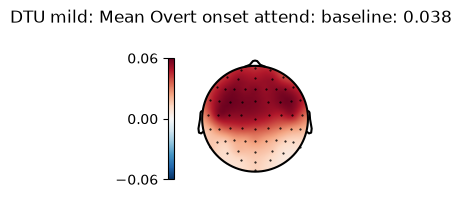

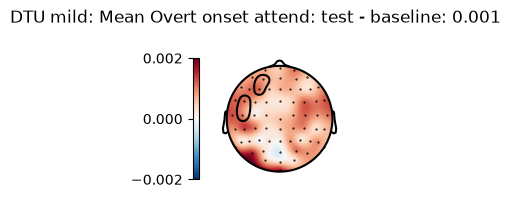

In [7]:
# Overt onset attend unique contribution (DTU mild)
# Brodbeck et al. 2020 ran this comparison too: attended overt onsets unique contribution, t = 3.34, p = .027.
data, diff, result = dtu_model_test('Overt onset attend', 'mild', 'overt-masked')
show_topomap_trio(data, diff, result, 'Overt onset attend', 'DTU mild', None)

In [8]:
display(result)
print(f"Overt onset attend (DTU mild): TFCE {tfce_summary(result)}")
ttest = test.TTestOneSample(f'roi_{METRIC}', data=diff, tail=1)
print(f"Overt onset attend (DTU mild): ROI model comparison t({ttest.df}) = {ttest.t:.3f}, p = {ttest.p:.4f}")

<TTestRelated 'r', 'model', 'test', 'baseline', 'subject' (n=18), tail=1, samples=10000, tfce=True, p = .026>

Overt onset attend (DTU mild): TFCE t_max = 2.83, p = 0.026
Overt onset attend (DTU mild): ROI model comparison t(17) = 2.859, p = 0.0054


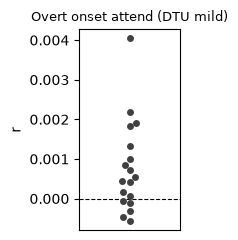

In [9]:
p = show_subject_swarm(diff, 'Overt onset attend', 'DTU mild')

<small>

**Brodbeck et al. 2020: Two talkers, overt onset ignore unique contribution**

- Overt ignored onsets: t_max = 3.82, p = 0.016 (weaker than masked)

</small>

/Users/joshuaighalo/Github Repositories/cocktail-cortical/analysis/experiment.py:1063: UserWarning: Warning: converting a masked element to nan.
  mean_value = float(data.mean())


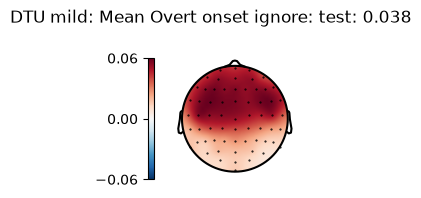

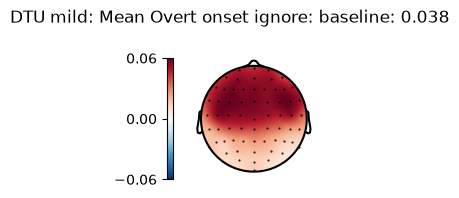

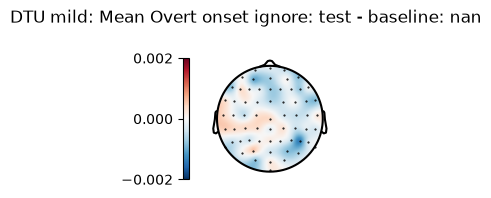

In [10]:
# Overt onset ignore unique contribution (DTU mild)
# Brodbeck et al. 2020 ran this comparison too: ignored overt onsets unique contribution, t = 3.82, p = .016.
data, diff, result = dtu_model_test('Overt onset ignore', 'mild', 'overt-masked')
show_topomap_trio(data, diff, result, 'Overt onset ignore', 'DTU mild', None)

In [11]:
display(result)
print(f"Overt onset ignore (DTU mild): TFCE {tfce_summary(result)}")
ttest = test.TTestOneSample(f'roi_{METRIC}', data=diff, tail=1)
print(f"Overt onset ignore (DTU mild): ROI model comparison t({ttest.df}) = {ttest.t:.3f}, p = {ttest.p:.4f}")

<TTestRelated 'r', 'model', 'test', 'baseline', 'subject' (n=18), tail=1, samples=10000, tfce=True, p = .867>

Overt onset ignore (DTU mild): TFCE t_max = 0.78, p = 0.867
Overt onset ignore (DTU mild): ROI model comparison t(17) = -1.303, p = 0.8950


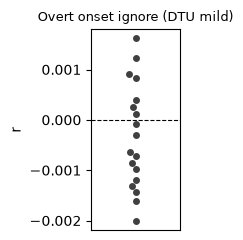

In [12]:
p = show_subject_swarm(diff, 'Overt onset ignore', 'DTU mild')

<small>

**Brodbeck et al. 2020: Two talkers, overt onset STRFs**

- Same positive-then-negative shape
- Early positive peak: not changed by attention (may even look bigger for ignored, because the attended negative peak starts early and overlaps it)
- Only the negative peak is changed by attention (attended only)

</small>

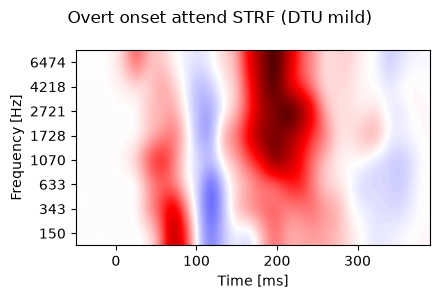

In [13]:
# Overt onset attend STRF (DTU mild)
strf = extract_strf(data_masked, f'{SPLIT_COLUMN}_on_overt_8')
p = plot.Array(strf * 1e3, title='Overt onset attend STRF (DTU mild)', interpolation=STRF_INTERPOLATION, xlim=PLOT_WINDOW)

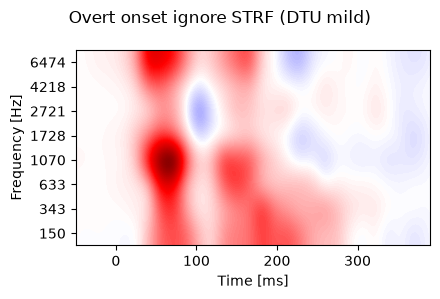

In [14]:
# Overt onset ignore STRF (DTU mild)
strf = extract_strf(data_masked, f'bg_{SPLIT_COLUMN}_on_overt_8')
p = plot.Array(strf * 1e3, title='Overt onset ignore STRF (DTU mild)', interpolation=STRF_INTERPOLATION, xlim=PLOT_WINDOW)

<small>

**Brodbeck et al. 2020: Two talkers, overt onset peak latencies**

- Positive peak: attended 72 ms, ignored 83 ms (mixture 72 ms)
- Negative peak: attended 133 ms (mixture 138 ms)
- Peak search window: 20 to 250 ms for the overt/masked analysis (this notebook: the same)

</small>

In [15]:
# Overt onset attend peak amplitude & timing (DTU mild)
data = extract_trf(data_masked, f'{SPLIT_COLUMN}_on_overt_8')
data = add_anchored_peak(data, 'positive', MASKED_POSITIVE_PEAK_WINDOW, kind='max')
data = add_anchored_peak(data, 'negative', MASKED_NEGATIVE_PEAK_WINDOW, kind='min')
print(f"Overt onset attend (DTU mild) positive peak: {data['positive_time'].mean() * 1e3:.0f} ms, amp {data['positive_amp'].mean():.4g}")
print(f"Overt onset attend (DTU mild) negative peak: {data['negative_time'].mean() * 1e3:.0f} ms, amp {data['negative_amp'].mean():.4g}")

Overt onset attend (DTU mild) positive peak: 193 ms, amp 0.004403
Overt onset attend (DTU mild) negative peak: 114 ms, amp -0.001228


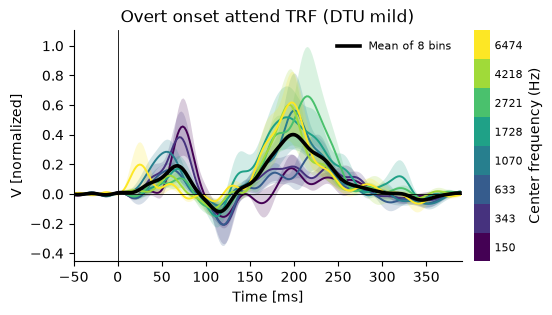

In [16]:
# Overt onset attend TRF per frequency bin (DTU mild)
p = plot_trf_bins(data_masked, f'{SPLIT_COLUMN}_on_overt_8', 'Overt onset attend TRF (DTU mild)')

In [17]:
# Overt onset ignore peak amplitude & timing (DTU mild)
data = extract_trf(data_masked, f'bg_{SPLIT_COLUMN}_on_overt_8')
data = add_anchored_peak(data, 'positive', MASKED_POSITIVE_PEAK_WINDOW, kind='max')
data = add_anchored_peak(data, 'negative', MASKED_NEGATIVE_PEAK_WINDOW, kind='min')
print(f"Overt onset ignore (DTU mild) positive peak: {data['positive_time'].mean() * 1e3:.0f} ms, amp {data['positive_amp'].mean():.4g}")
print(f"Overt onset ignore (DTU mild) negative peak: {data['negative_time'].mean() * 1e3:.0f} ms, amp {data['negative_amp'].mean():.4g}")

Overt onset ignore (DTU mild) positive peak: 64 ms, amp 0.002561
Overt onset ignore (DTU mild) negative peak: 113 ms, amp -0.0002701


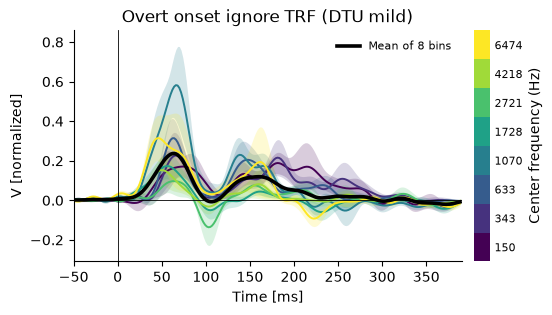

In [18]:
# Overt onset ignore TRF per frequency bin (DTU mild)
p = plot_trf_bins(data_masked, f'bg_{SPLIT_COLUMN}_on_overt_8', 'Overt onset ignore TRF (DTU mild)')

In [19]:
# Overt onset peak comparison across attend and ignore (DTU mild)
dss = []
for role_name, column in (('attend', f'{SPLIT_COLUMN}_on_overt_8'), ('ignore', f'bg_{SPLIT_COLUMN}_on_overt_8')):
    ds = extract_trf(data_masked, column)
    ds[:, 'role'] = role_name
    dss.append(ds)
data = combine(dss)
data = add_anchored_peak(data, 'positive', MASKED_POSITIVE_PEAK_WINDOW, kind='max', by='role')
data = add_anchored_peak(data, 'negative', MASKED_NEGATIVE_PEAK_WINDOW, kind='min', by='role')

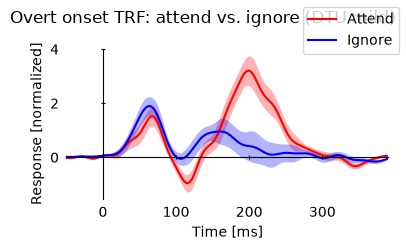

In [20]:
# The overt onset TRF waveform attend/ignore were each just measured
# from, overlaid so their shape and relative timing are visible
# directly, not just as extracted peak numbers below.
p = plot.UTSStat('trf_sm*1e3', 'role', data=data, match='subject', within_subject_error=True, frame='t', h=2.5, w=4, xlim=PLOT_WINDOW,
                  title='Overt onset TRF: attend vs. ignore (DTU mild)', labels={'attend': 'Attend', 'ignore': 'Ignore'}, colors={'attend': 'red', 'ignore': 'blue'})

In [21]:
print_peak_table(data, 'positive', 'role')
print_peak_table(data, 'negative', 'role')


positive peak
subject   role         time (ms)           amp
S1        attend             205      0.002119
S2        attend             187      0.005341
S3        attend             181     0.0004828
S4        attend             175      0.002108
S5        attend             222      0.008197
S6        attend             203     0.0004115
S7        attend             195      0.007451
S8        attend             193      0.008306
S9        attend             179      0.008384
S10       attend             177     0.0008981
S11       attend             189      0.000914
S12       attend             197      0.005882
S13       attend             197      0.002726
S14       attend             207      0.009826
S15       attend             197      0.003825
S16       attend             185      0.000928
S17       attend             175      0.001048
S18       attend             209       0.01041
S1        ignore              70      0.003575
S2        ignore              56      0.00689

In [22]:
display(test.pairwise('positive_time', 'role', match='subject', data=data, corr=False, title='overt onset positive peak latency: attend vs. ignore'))
display(test.pairwise('negative_time', 'role', match='subject', data=data, corr=False, title='overt onset negative peak latency: attend vs. ignore'))

,ignore
attend,t17 = 28.73*** p < .001


,ignore
attend,t17 = 0.47 p = .644


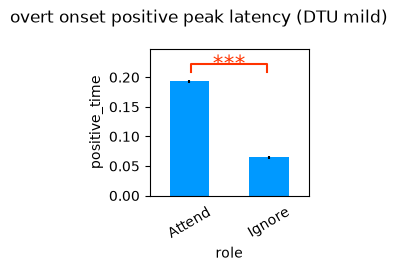

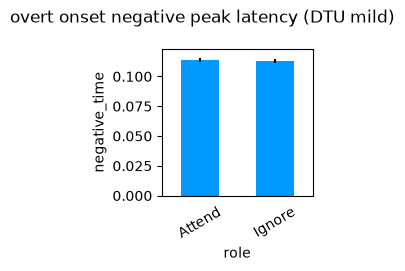

In [23]:
p = plot.Barplot('positive_time', 'role', match='subject', data=data, h=2.5, w=2.5, labels=LABELS_ROLE, corr=False, title='overt onset positive peak latency (DTU mild)')
p.set_xtick_rotation(30)
p = plot.Barplot('negative_time', 'role', match='subject', data=data, h=2.5, w=2.5, labels=LABELS_ROLE, corr=False, title='overt onset negative peak latency (DTU mild)')
p.set_xtick_rotation(30)

In [24]:
display(test.pairwise('positive_amp', 'role', match='subject', data=data, corr=False, title='overt onset positive peak amplitude: attend vs. ignore'))
display(test.pairwise('negative_amp', 'role', match='subject', data=data, corr=False, title='overt onset negative peak amplitude: attend vs. ignore'))

,ignore
attend,t17 = 1.75 p = .098


,ignore
attend,t17 = -1.98 p = .064


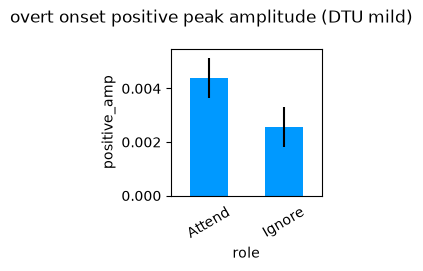

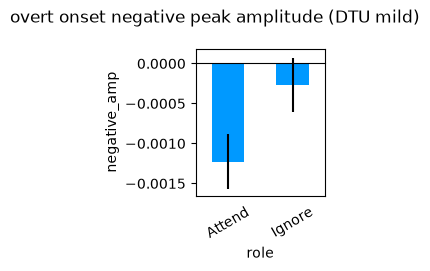

In [25]:
p = plot.Barplot('positive_amp', 'role', match='subject', data=data, h=2.5, w=2.5, labels=LABELS_ROLE, corr=False, title='overt onset positive peak amplitude (DTU mild)')
p.set_xtick_rotation(30)
p = plot.Barplot('negative_amp', 'role', match='subject', data=data, h=2.5, w=2.5, labels=LABELS_ROLE, corr=False, title='overt onset negative peak amplitude (DTU mild)')
p.set_xtick_rotation(30)

<small>

**Brodbeck et al. 2020: Two talkers, overt onset attention effect**

- No attention effect on the early positive peak
- Attention effect on the later negative peak, starting near the top of the positive peak

</small>

Permutation test:   0%|          | 0/10000 [00:00<?, ? permutations/s]

Overt onset attention effect: attend - ignore (DTU mild): bins that differ from 0 somewhere: 633 Hz


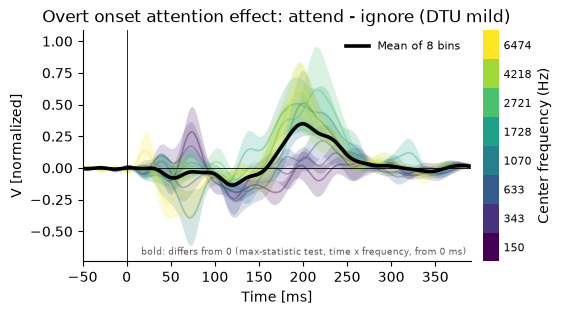

In [26]:
# Overt onset attention effect: attend - ignore (DTU mild)
p = plot_trf_bins(data_masked, f'{SPLIT_COLUMN}_on_overt_8', 'Overt onset attention effect: attend - ignore (DTU mild)', subtract=f'bg_{SPLIT_COLUMN}_on_overt_8')

Permutation test:   0%|          | 0/10000 [00:00<?, ? permutations/s]

Overt onset attention effect: attend - ignore (DTU mild): differs from 0 (max-statistic permutation test from 0 ms, two-tailed; ranges < 10 ms apart joined) at 189-199 ms (p = 0.025)


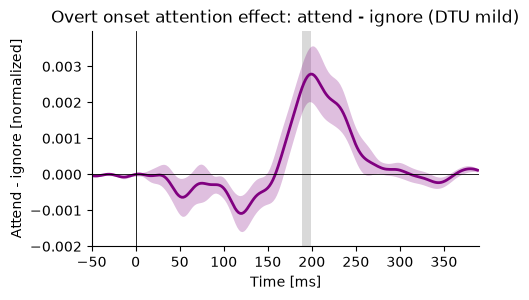

In [27]:
# The same attention effect as one waveform: summed over the frequency bins, mean +- 1 SEM across
# subjects; grey where attend - ignore differs from 0 (TFCE over time, two-tailed).
p = plot_attention_effect(data_masked, f'{SPLIT_COLUMN}_on_overt_8', f'bg_{SPLIT_COLUMN}_on_overt_8', 'Overt onset attention effect: attend - ignore (DTU mild)')

## DTU mild (masked onset)

<small>

**Brodbeck et al. 2020: Two talkers, masked onset attend unique contribution**

- Masked attended onsets: t_max = 8.42, p < 0.001

</small>

/Users/joshuaighalo/Github Repositories/cocktail-cortical/analysis/experiment.py:1063: UserWarning: Warning: converting a masked element to nan.
  mean_value = float(data.mean())


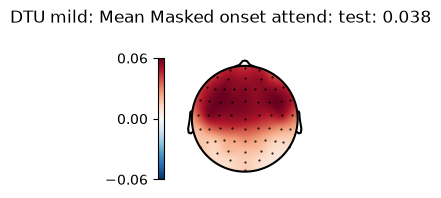

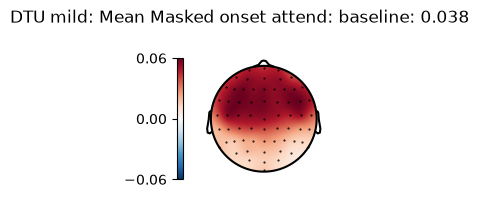

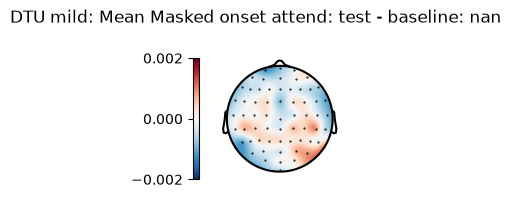

In [28]:
# Masked onset attend unique contribution (DTU mild)
# Brodbeck et al. 2020 ran this comparison too: attended masked onsets unique contribution, t = 8.42, p < .001 - the strongest of the four masking predictors.
data, diff, result = dtu_model_test('Masked onset attend', 'mild', 'overt-masked')
show_topomap_trio(data, diff, result, 'Masked onset attend', 'DTU mild', None)

In [29]:
display(result)
print(f"Masked onset attend (DTU mild): TFCE {tfce_summary(result)}")
ttest = test.TTestOneSample(f'roi_{METRIC}', data=diff, tail=1)
print(f"Masked onset attend (DTU mild): ROI model comparison t({ttest.df}) = {ttest.t:.3f}, p = {ttest.p:.4f}")

<TTestRelated 'r', 'model', 'test', 'baseline', 'subject' (n=18), tail=1, samples=10000, tfce=True, p = .939>

Masked onset attend (DTU mild): TFCE t_max = 0.59, p = 0.939
Masked onset attend (DTU mild): ROI model comparison t(17) = -1.015, p = 0.8377


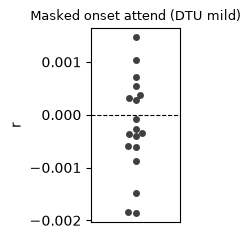

In [30]:
p = show_subject_swarm(diff, 'Masked onset attend', 'DTU mild')

<small>

**Brodbeck et al. 2020: Two talkers, masked onset ignore unique contribution**

- Masked ignored onsets: t_max = 5.23, p < 0.001
- Key finding: the brain recovers masked onsets even for the ignored speaker

</small>

/Users/joshuaighalo/Github Repositories/cocktail-cortical/analysis/experiment.py:1063: UserWarning: Warning: converting a masked element to nan.
  mean_value = float(data.mean())


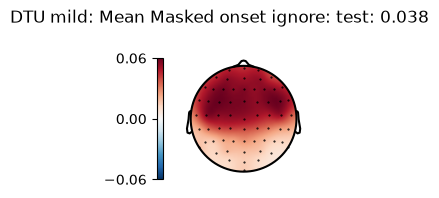

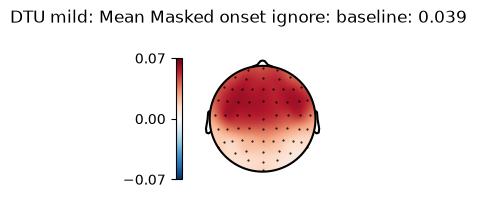

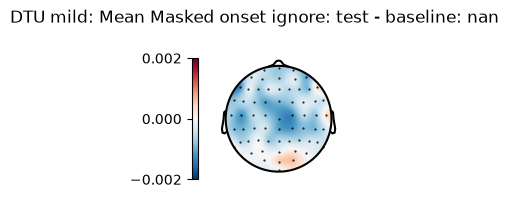

In [31]:
# Masked onset ignore unique contribution (DTU mild)
# Brodbeck et al. 2020 ran this comparison too: ignored masked onsets unique contribution, t = 5.23, p < .001 - the brain recovers masked information even for the ignored speaker.
data, diff, result = dtu_model_test('Masked onset ignore', 'mild', 'overt-masked')
show_topomap_trio(data, diff, result, 'Masked onset ignore', 'DTU mild', None)

In [32]:
display(result)
print(f"Masked onset ignore (DTU mild): TFCE {tfce_summary(result)}")
ttest = test.TTestOneSample(f'roi_{METRIC}', data=diff, tail=1)
print(f"Masked onset ignore (DTU mild): ROI model comparison t({ttest.df}) = {ttest.t:.3f}, p = {ttest.p:.4f}")

<TTestRelated 'r', 'model', 'test', 'baseline', 'subject' (n=18), tail=1, samples=10000, tfce=True, p = 1.000>

Masked onset ignore (DTU mild): TFCE t_max = -0.40, p = 1.000
Masked onset ignore (DTU mild): ROI model comparison t(17) = -2.286, p = 0.9823


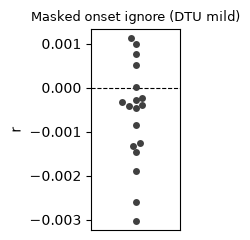

In [33]:
p = show_subject_swarm(diff, 'Masked onset ignore', 'DTU mild')

<small>

**Brodbeck et al. 2020: Two talkers, masked onset STRFs**

- Same positive-then-negative shape, but later than overt onsets
- Even the early positive peak is bigger for the attended speaker (an early attention effect)

</small>

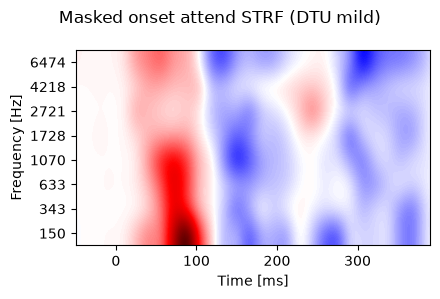

In [34]:
# Masked onset attend STRF (DTU mild)
strf = extract_strf(data_masked, f'{SPLIT_COLUMN}_on_masked_8')
p = plot.Array(strf * 1e3, title='Masked onset attend STRF (DTU mild)', interpolation=STRF_INTERPOLATION, xlim=PLOT_WINDOW)

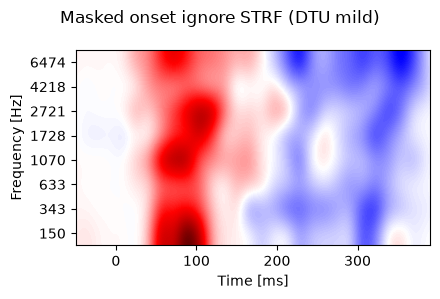

In [35]:
# Masked onset ignore STRF (DTU mild)
strf = extract_strf(data_masked, f'bg_{SPLIT_COLUMN}_on_masked_8')
p = plot.Array(strf * 1e3, title='Masked onset ignore STRF (DTU mild)', interpolation=STRF_INTERPOLATION, xlim=PLOT_WINDOW)

<small>

**Brodbeck et al. 2020: Two talkers, masked onset peak latencies**

- Positive peak: attended 91 ms, ignored 97 ms
- Negative peak: attended 182 ms
- Masked onsets lag overt onsets by at least 15 ms at each peak (about 20 ms on average)
- Peak search window: 20 to 250 ms (this notebook: the same)

</small>

In [36]:
# Masked onset attend peak amplitude & timing (DTU mild)
data = extract_trf(data_masked, f'{SPLIT_COLUMN}_on_masked_8')
data = add_anchored_peak(data, 'positive', MASKED_POSITIVE_PEAK_WINDOW, kind='max')
data = add_anchored_peak(data, 'negative', MASKED_NEGATIVE_PEAK_WINDOW, kind='min')
print(f"Masked onset attend (DTU mild) positive peak: {data['positive_time'].mean() * 1e3:.0f} ms, amp {data['positive_amp'].mean():.4g}")
print(f"Masked onset attend (DTU mild) negative peak: {data['negative_time'].mean() * 1e3:.0f} ms, amp {data['negative_amp'].mean():.4g}")

Masked onset attend (DTU mild) positive peak: 76 ms, amp 0.001484
Masked onset attend (DTU mild) negative peak: 158 ms, amp -0.001018


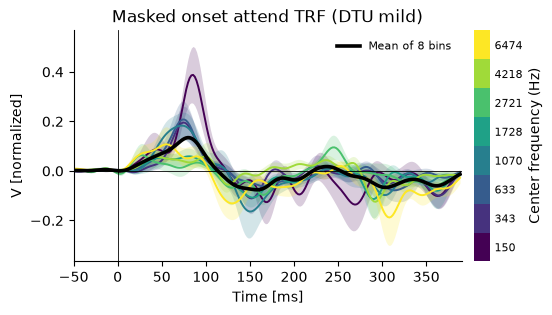

In [37]:
# Masked onset attend TRF per frequency bin (DTU mild)
p = plot_trf_bins(data_masked, f'{SPLIT_COLUMN}_on_masked_8', 'Masked onset attend TRF (DTU mild)')

In [38]:
# Masked onset ignore peak amplitude & timing (DTU mild)
data = extract_trf(data_masked, f'bg_{SPLIT_COLUMN}_on_masked_8')
data = add_anchored_peak(data, 'positive', MASKED_POSITIVE_PEAK_WINDOW, kind='max')
data = add_anchored_peak(data, 'negative', MASKED_NEGATIVE_PEAK_WINDOW, kind='min')
print(f"Masked onset ignore (DTU mild) positive peak: {data['positive_time'].mean() * 1e3:.0f} ms, amp {data['positive_amp'].mean():.4g}")
print(f"Masked onset ignore (DTU mild) negative peak: {data['negative_time'].mean() * 1e3:.0f} ms, amp {data['negative_amp'].mean():.4g}")

Masked onset ignore (DTU mild) positive peak: 86 ms, amp 0.001618
Masked onset ignore (DTU mild) negative peak: 230 ms, amp -0.0007145


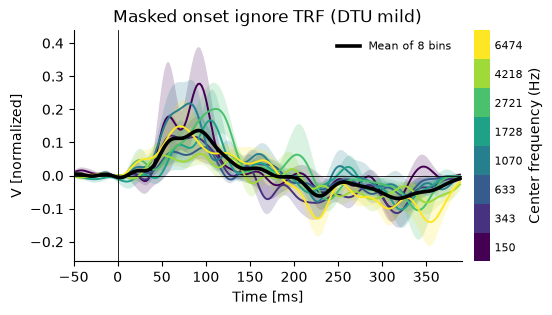

In [39]:
# Masked onset ignore TRF per frequency bin (DTU mild)
p = plot_trf_bins(data_masked, f'bg_{SPLIT_COLUMN}_on_masked_8', 'Masked onset ignore TRF (DTU mild)')

In [40]:
# Masked onset peak comparison across attend and ignore (DTU mild)
dss = []
for role_name, column in (('attend', f'{SPLIT_COLUMN}_on_masked_8'), ('ignore', f'bg_{SPLIT_COLUMN}_on_masked_8')):
    ds = extract_trf(data_masked, column)
    ds[:, 'role'] = role_name
    dss.append(ds)
data = combine(dss)
data = add_anchored_peak(data, 'positive', MASKED_POSITIVE_PEAK_WINDOW, kind='max', by='role')
data = add_anchored_peak(data, 'negative', MASKED_NEGATIVE_PEAK_WINDOW, kind='min', by='role')

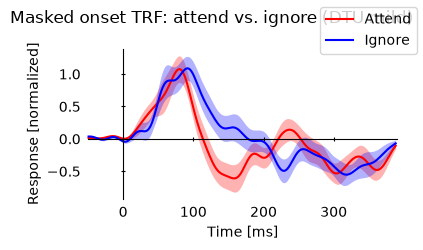

In [41]:
# The masked onset TRF waveform attend/ignore were each just measured
# from, overlaid so their shape and relative timing are visible
# directly, not just as extracted peak numbers below.
p = plot.UTSStat('trf_sm*1e3', 'role', data=data, match='subject', within_subject_error=True, frame='t', h=2.5, w=4, xlim=PLOT_WINDOW,
                  title='Masked onset TRF: attend vs. ignore (DTU mild)', labels={'attend': 'Attend', 'ignore': 'Ignore'}, colors={'attend': 'red', 'ignore': 'blue'})

In [42]:
print_peak_table(data, 'positive', 'role')
print_peak_table(data, 'negative', 'role')


positive peak
subject   role         time (ms)           amp
S1        attend              80      0.002578
S2        attend              72      0.002187
S3        attend              86     0.0004613
S4        attend              86      0.001144
S5        attend              56       0.00193
S6        attend              56     0.0001063
S7        attend              88      0.001576
S8        attend              88     0.0005268
S9        attend              80       0.00101
S10       attend              76      0.002559
S11       attend              74      0.000835
S12       attend              56      0.001131
S13       attend             101      0.002081
S14       attend              89       0.00196
S15       attend              78      0.001357
S16       attend              80      0.002593
S17       attend              66     0.0006112
S18       attend              56      0.002065
S1        ignore              86      0.001829
S2        ignore              74      0.00357

In [43]:
display(test.pairwise('positive_time', 'role', match='subject', data=data, corr=False, title='masked onset positive peak latency: attend vs. ignore'))
display(test.pairwise('negative_time', 'role', match='subject', data=data, corr=False, title='masked onset negative peak latency: attend vs. ignore'))

,ignore
attend,t17 = -1.80 p = .090


,ignore
attend,t17 = -13.46*** p < .001


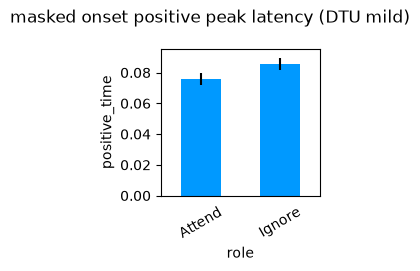

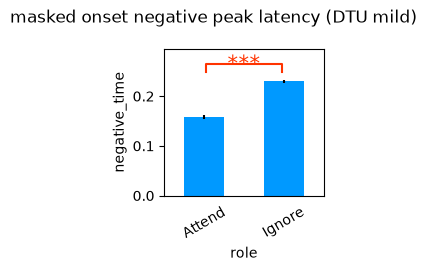

In [44]:
p = plot.Barplot('positive_time', 'role', match='subject', data=data, h=2.5, w=2.5, labels=LABELS_ROLE, corr=False, title='masked onset positive peak latency (DTU mild)')
p.set_xtick_rotation(30)
p = plot.Barplot('negative_time', 'role', match='subject', data=data, h=2.5, w=2.5, labels=LABELS_ROLE, corr=False, title='masked onset negative peak latency (DTU mild)')
p.set_xtick_rotation(30)

In [45]:
display(test.pairwise('positive_amp', 'role', match='subject', data=data, corr=False, title='masked onset positive peak amplitude: attend vs. ignore'))
display(test.pairwise('negative_amp', 'role', match='subject', data=data, corr=False, title='masked onset negative peak amplitude: attend vs. ignore'))

,ignore
attend,t17 = -0.41 p = .685


,ignore
attend,t17 = -1.05 p = .310


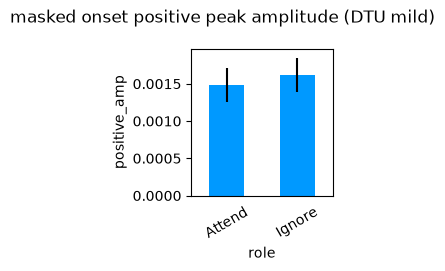

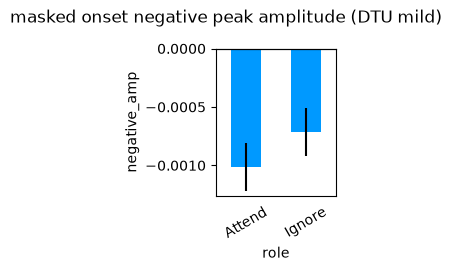

In [46]:
p = plot.Barplot('positive_amp', 'role', match='subject', data=data, h=2.5, w=2.5, labels=LABELS_ROLE, corr=False, title='masked onset positive peak amplitude (DTU mild)')
p.set_xtick_rotation(30)
p = plot.Barplot('negative_amp', 'role', match='subject', data=data, h=2.5, w=2.5, labels=LABELS_ROLE, corr=False, title='masked onset negative peak amplitude (DTU mild)')
p.set_xtick_rotation(30)

<small>

**Brodbeck et al. 2020: Two talkers, masked onset attention effect**

- Early positive peak bigger for attended than ignored, despite the following negative peak

</small>

Permutation test:   0%|          | 0/10000 [00:00<?, ? permutations/s]

Masked onset attention effect: attend - ignore (DTU mild): bins that differ from 0 somewhere: none


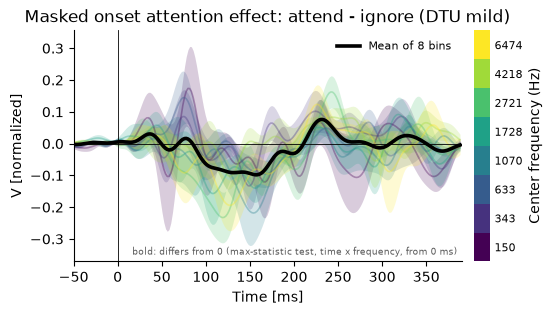

In [47]:
# Masked onset attention effect: attend - ignore (DTU mild)
p = plot_trf_bins(data_masked, f'{SPLIT_COLUMN}_on_masked_8', 'Masked onset attention effect: attend - ignore (DTU mild)', subtract=f'bg_{SPLIT_COLUMN}_on_masked_8')

Permutation test:   0%|          | 0/10000 [00:00<?, ? permutations/s]

Masked onset attention effect: attend - ignore (DTU mild): no time range differs from 0 (max-statistic permutation test from 0 ms, two-tailed, smallest p = 0.292)


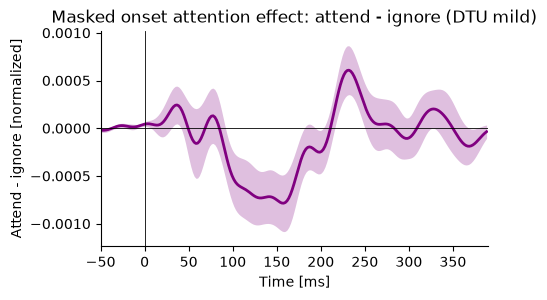

In [48]:
# The same attention effect as one waveform: summed over the frequency bins, mean +- 1 SEM across
# subjects; grey where attend - ignore differs from 0 (TFCE over time, two-tailed).
p = plot_attention_effect(data_masked, f'{SPLIT_COLUMN}_on_masked_8', f'bg_{SPLIT_COLUMN}_on_masked_8', 'Masked onset attention effect: attend - ignore (DTU mild)')

<small>

**Brodbeck et al. 2020: Two talkers, overt vs masked peaks, attended**

- Positive peak later for masked: 91 vs 72 ms, t(25) = 2.85, p = 0.009
- Negative peak later for masked: 182 vs 133 ms, t(25) = 4.45, p < 0.001

</small>

In [49]:
# Overt vs. masked peak comparison, attend (DTU mild)
# Brodbeck et al. 2020 ran this comparison too: attended overt 72ms vs. attended masked 91ms (t=2.85,p=.009); combined (not stream-split) late negative peak, overt 133ms vs. masked 182ms (t=4.45,p<.001).
dss = []
for masking, column in (('overt', f'{SPLIT_COLUMN}_on_overt_8'), ('masked', f'{SPLIT_COLUMN}_on_masked_8')):
    ds = extract_trf(data_masked, column)
    ds[:, 'masking'] = masking
    dss.append(ds)
data = combine(dss)
data = add_anchored_peak(data, 'positive', MASKED_POSITIVE_PEAK_WINDOW, kind='max', by='masking')
data = add_anchored_peak(data, 'negative', MASKED_NEGATIVE_PEAK_WINDOW, kind='min', by='masking')

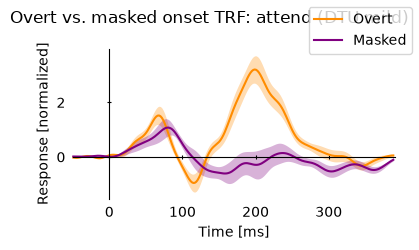

In [50]:
# Overt and masked onset TRFs of the attended speaker, overlaid
p = plot.UTSStat('trf_sm*1e3', 'masking', data=data, match='subject', within_subject_error=True, frame='t', h=2.5, w=4, xlim=PLOT_WINDOW,
                  title='Overt vs. masked onset TRF: attend (DTU mild)', labels=LABELS_MASKING, colors=COLORS_MASKING)

In [51]:
print_peak_table(data, 'positive', 'masking')
print_peak_table(data, 'negative', 'masking')


positive peak
subject   masking      time (ms)           amp
S1        overt              205      0.002119
S2        overt              187      0.005341
S3        overt              181     0.0004828
S4        overt              175      0.002108
S5        overt              222      0.008197
S6        overt              203     0.0004115
S7        overt              195      0.007451
S8        overt              193      0.008306
S9        overt              179      0.008384
S10       overt              177     0.0008981
S11       overt              189      0.000914
S12       overt              197      0.005882
S13       overt              197      0.002726
S14       overt              207      0.009826
S15       overt              197      0.003825
S16       overt              185      0.000928
S17       overt              175      0.001048
S18       overt              209       0.01041
S1        masked              80      0.002578
S2        masked              72      0.00218

In [52]:
display(test.pairwise('positive_time', 'masking', match='subject', data=data, corr=False, title='attend positive peak latency: overt vs. masked'))
display(test.pairwise('negative_time', 'masking', match='subject', data=data, corr=False, title='attend negative peak latency: overt vs. masked'))

,masked
overt,t17 = 23.26*** p < .001


,masked
overt,t17 = -8.91*** p < .001


In [53]:
display(test.pairwise('positive_amp', 'masking', match='subject', data=data, corr=False, title='attend positive peak amplitude: overt vs. masked'))
display(test.pairwise('negative_amp', 'masking', match='subject', data=data, corr=False, title='attend negative peak amplitude: overt vs. masked'))

,masked
overt,t17 = 3.50** p = .003


,masked
overt,t17 = -0.45 p = .659


<small>

**Brodbeck et al. 2020: Two talkers, overt vs masked peaks, ignored**

- Positive peak later for masked: 97 vs 83 ms, t(25) = 6.11, p < 0.001

</small>

In [54]:
# Overt vs. masked peak comparison, ignore (DTU mild)
# Brodbeck et al. 2020 ran this comparison too: ignored overt 83ms vs. ignored masked 97ms (t=6.11,p<.001); combined (not stream-split) late negative peak, overt 133ms vs. masked 182ms (t=4.45,p<.001).
dss = []
for masking, column in (('overt', f'bg_{SPLIT_COLUMN}_on_overt_8'), ('masked', f'bg_{SPLIT_COLUMN}_on_masked_8')):
    ds = extract_trf(data_masked, column)
    ds[:, 'masking'] = masking
    dss.append(ds)
data = combine(dss)
data = add_anchored_peak(data, 'positive', MASKED_POSITIVE_PEAK_WINDOW, kind='max', by='masking')
data = add_anchored_peak(data, 'negative', MASKED_NEGATIVE_PEAK_WINDOW, kind='min', by='masking')

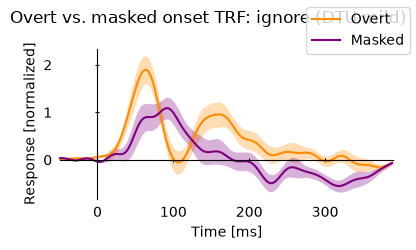

In [55]:
# Overt and masked onset TRFs of the ignored speaker, overlaid
p = plot.UTSStat('trf_sm*1e3', 'masking', data=data, match='subject', within_subject_error=True, frame='t', h=2.5, w=4, xlim=PLOT_WINDOW,
                  title='Overt vs. masked onset TRF: ignore (DTU mild)', labels=LABELS_MASKING, colors=COLORS_MASKING)

In [56]:
print_peak_table(data, 'positive', 'masking')
print_peak_table(data, 'negative', 'masking')


positive peak
subject   masking      time (ms)           amp
S1        overt               70      0.003575
S2        overt               56      0.006898
S3        overt               82      0.001424
S4        overt               72      0.005137
S5        overt               76     0.0009284
S6        overt               70      0.002436
S7        overt               78    -0.0002287
S8        overt               58      0.001702
S9        overt               43     0.0006697
S10       overt               68       0.00518
S11       overt               43      0.002052
S12       overt               48      0.002336
S13       overt               64        0.0022
S14       overt               56      0.004216
S15       overt               46      0.005054
S16       overt               72      0.001843
S17       overt               88     0.0001695
S18       overt               70     0.0005027
S1        masked              86      0.001829
S2        masked              74      0.00357

In [57]:
display(test.pairwise('positive_time', 'masking', match='subject', data=data, corr=False, title='ignore positive peak latency: overt vs. masked'))
display(test.pairwise('negative_time', 'masking', match='subject', data=data, corr=False, title='ignore negative peak latency: overt vs. masked'))

,masked
overt,t17 = -4.35*** p < .001


,masked
overt,t17 = -26.89*** p < .001


In [58]:
display(test.pairwise('positive_amp', 'masking', match='subject', data=data, corr=False, title='ignore positive peak amplitude: overt vs. masked'))
display(test.pairwise('negative_amp', 'masking', match='subject', data=data, corr=False, title='ignore negative peak amplitude: overt vs. masked'))

,masked
overt,t17 = 2.10 p = .051


,masked
overt,t17 = 1.93 p = .071


<small>

**Brodbeck et al. 2020: Two talkers, stream x masking interaction**

- ANOVA on positive peak amplitude (attended/ignored x overt/masked): F(1,25) = 24.45, p < 0.001
- Overt onsets: no early attention effect; masked onsets: early attention effect

</small>

In [59]:
# Stream x masking interaction on peak amplitude (DTU mild)
# Brodbeck et al. 2020 ran this comparison too: stream x masking interaction, F(1,25) = 24.45, p < .001 - overt onsets show no early attention effect, masked onsets do.
dss = []
for stream_name, is_attend in (('attend', True), ('ignore', False)):
    for masking_name in ('overt', 'masked'):
        prefix = '' if is_attend else 'bg_'
        column = f'{prefix}{SPLIT_COLUMN}_on_{masking_name}_8'
        ds = extract_trf(data_masked, column)
        ds[:, 'stream'] = stream_name
        ds[:, 'masking'] = masking_name
        dss.append(ds)
data = combine(dss)
data = add_anchored_peak(data, 'positive', MASKED_POSITIVE_PEAK_WINDOW, kind='max', by=('stream', 'masking'))
display(test.ANOVA('positive_amp', 'stream * masking * subject', data=data, title='stream x masking interaction (DTU mild)'))

<ANOVA: positive_amp ~ stream + masking + stream x masking + subject + stream x subject + masking x subject + stream x masking x subject
  
  stream x masking interaction (DTU mild)
  
                       SS   df     MS   MS(denom)   df(denom)          F        p
  -------------------------------------------------------------------------------
  stream             0.00    1   0.00        0.00          17    2.46        .135
  masking            0.00    1   0.00        0.00          17   26.81***   < .001
  stream x masking   0.00    1   0.00        0.00          17    3.16        .093
  -------------------------------------------------------------------------------
  Total              0.00   71
>

## DTU mild (intensity-level control)

### Overt and masked onsets together

Overt and masked onsets are made from the same syllable starts, so they rise and fall together. Removed one at a time (the tests above), each can stand in for the other, and both can look useless even when the speaker's onsets matter. Here both are removed at once: if the speaker's onsets add predictive power, this joint test should show it, as the unsplit onset does (the reference tests below, the same onsets unsplit, at the speaker's level in the mixture).

- Joint test significant, one-at-a-time tests not: the information is there, but overt and masked cannot be told apart in these data.
- Joint test not significant either: the overt/masked predictors carry less than the unsplit onsets.

/Users/joshuaighalo/Github Repositories/cocktail-cortical/analysis/experiment.py:1063: UserWarning: Warning: converting a masked element to nan.
  mean_value = float(data.mean())


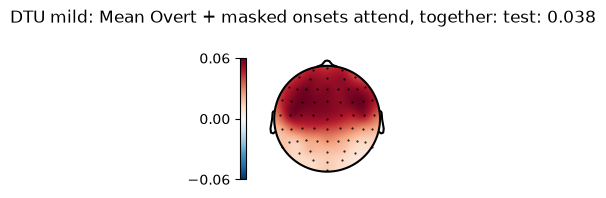

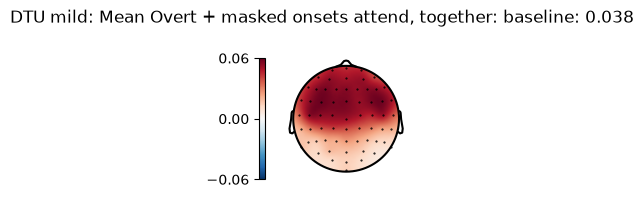

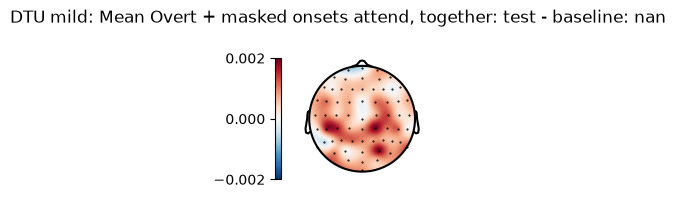

In [60]:
# Overt + masked onsets attend, together (DTU mild)
# both of the attended speaker's onset predictors removed at once
data, diff, result = dtu_model_test('Overt + masked onsets attend, together', 'mild', 'overt-masked')
show_topomap_trio(data, diff, result, 'Overt + masked onsets attend, together', 'DTU mild', None)

In [61]:
display(result)
print(f"Overt + masked onsets attend, together (DTU mild): TFCE {tfce_summary(result)}")
ttest = test.TTestOneSample(f'roi_{METRIC}', data=diff, tail=1)
print(f"Overt + masked onsets attend, together (DTU mild): ROI model comparison t({ttest.df}) = {ttest.t:.3f}, p = {ttest.p:.4f}")

<TTestRelated 'r', 'model', 'test', 'baseline', 'subject' (n=18), tail=1, samples=10000, tfce=True, p = .167>

Overt + masked onsets attend, together (DTU mild): TFCE t_max = 2.23, p = 0.167
Overt + masked onsets attend, together (DTU mild): ROI model comparison t(17) = 1.768, p = 0.0475


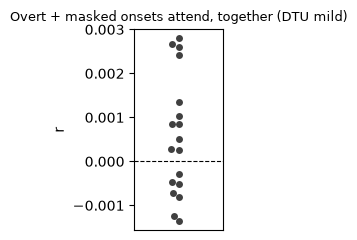

In [62]:
p = show_subject_swarm(diff, 'Overt + masked onsets attend, together', 'DTU mild')

/Users/joshuaighalo/Github Repositories/cocktail-cortical/analysis/experiment.py:1063: UserWarning: Warning: converting a masked element to nan.
  mean_value = float(data.mean())


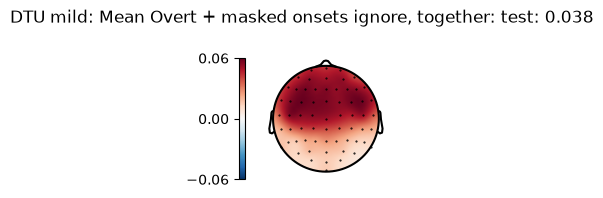

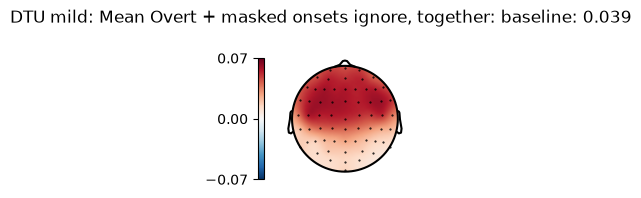

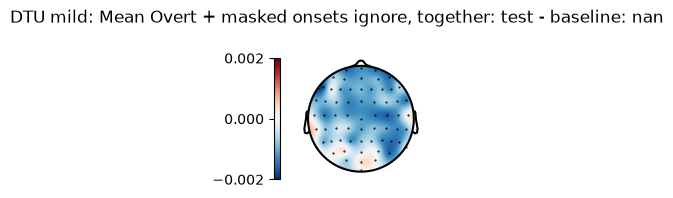

In [63]:
# Overt + masked onsets ignore, together (DTU mild)
# both of the ignored speaker's onset predictors removed at once
data, diff, result = dtu_model_test('Overt + masked onsets ignore, together', 'mild', 'overt-masked')
show_topomap_trio(data, diff, result, 'Overt + masked onsets ignore, together', 'DTU mild', None)

In [64]:
display(result)
print(f"Overt + masked onsets ignore, together (DTU mild): TFCE {tfce_summary(result)}")
ttest = test.TTestOneSample(f'roi_{METRIC}', data=diff, tail=1)
print(f"Overt + masked onsets ignore, together (DTU mild): ROI model comparison t({ttest.df}) = {ttest.t:.3f}, p = {ttest.p:.4f}")

<TTestRelated 'r', 'model', 'test', 'baseline', 'subject' (n=18), tail=1, samples=10000, tfce=True, p = 1.000>

Overt + masked onsets ignore, together (DTU mild): TFCE t_max = -0.07, p = 1.000
Overt + masked onsets ignore, together (DTU mild): ROI model comparison t(17) = -2.781, p = 0.9936


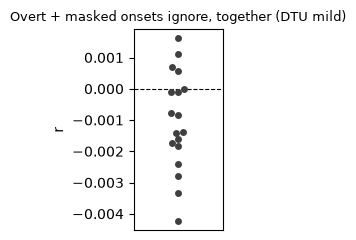

In [65]:
p = show_subject_swarm(diff, 'Overt + masked onsets ignore, together', 'DTU mild')

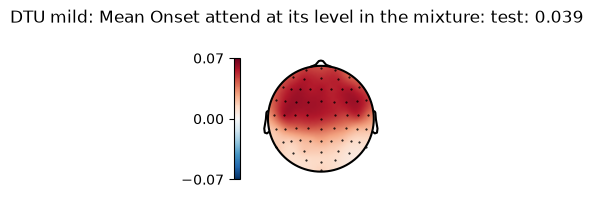

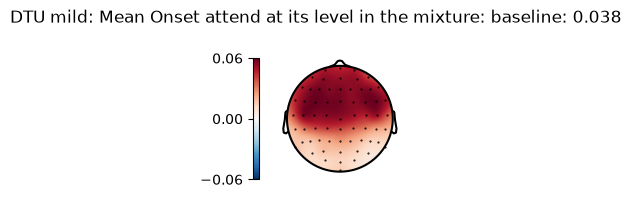

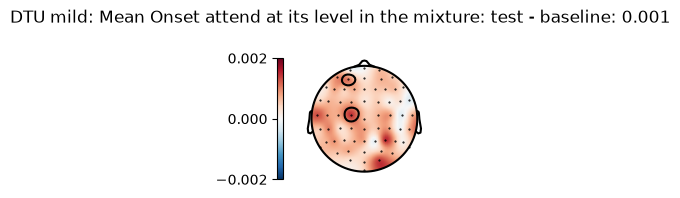

In [66]:
# Onset attend at its level in the mixture (DTU mild)
# reference: the same onsets unsplit, removed from FULL_INMIX
data, diff, result = dtu_model_test('Onset attend at its level in the mixture', 'mild', 'overt-masked')
show_topomap_trio(data, diff, result, 'Onset attend at its level in the mixture', 'DTU mild', None)

In [67]:
display(result)
print(f"Onset attend at its level in the mixture (DTU mild): TFCE {tfce_summary(result)}")
ttest = test.TTestOneSample(f'roi_{METRIC}', data=diff, tail=1)
print(f"Onset attend at its level in the mixture (DTU mild): ROI model comparison t({ttest.df}) = {ttest.t:.3f}, p = {ttest.p:.4f}")

<TTestRelated 'r', 'model', 'test', 'baseline', 'subject' (n=18), tail=1, samples=10000, tfce=True, p = .025>

Onset attend at its level in the mixture (DTU mild): TFCE t_max = 3.17, p = 0.025
Onset attend at its level in the mixture (DTU mild): ROI model comparison t(17) = 2.947, p = 0.0045


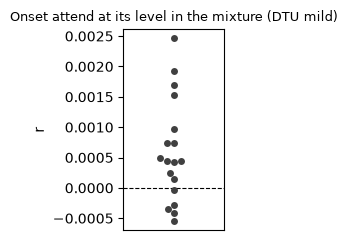

In [68]:
p = show_subject_swarm(diff, 'Onset attend at its level in the mixture', 'DTU mild')

/Users/joshuaighalo/Github Repositories/cocktail-cortical/analysis/experiment.py:1063: UserWarning: Warning: converting a masked element to nan.
  mean_value = float(data.mean())


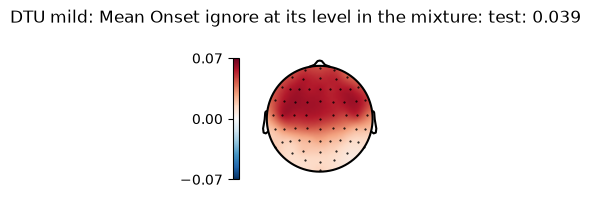

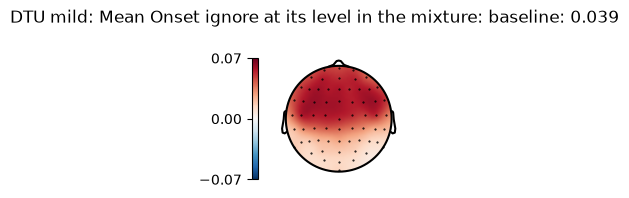

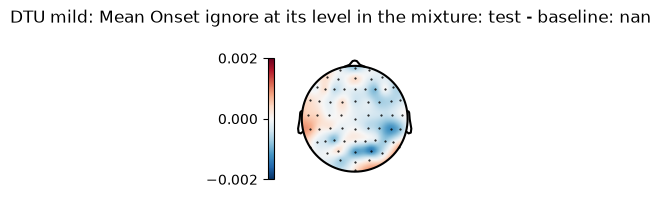

In [69]:
# Onset ignore at its level in the mixture (DTU mild)
# reference: the same onsets unsplit, removed from FULL_INMIX
data, diff, result = dtu_model_test('Onset ignore at its level in the mixture', 'mild', 'overt-masked')
show_topomap_trio(data, diff, result, 'Onset ignore at its level in the mixture', 'DTU mild', None)

In [70]:
display(result)
print(f"Onset ignore at its level in the mixture (DTU mild): TFCE {tfce_summary(result)}")
ttest = test.TTestOneSample(f'roi_{METRIC}', data=diff, tail=1)
print(f"Onset ignore at its level in the mixture (DTU mild): ROI model comparison t({ttest.df}) = {ttest.t:.3f}, p = {ttest.p:.4f}")

<TTestRelated 'r', 'model', 'test', 'baseline', 'subject' (n=18), tail=1, samples=10000, tfce=True, p = .632>

Onset ignore at its level in the mixture (DTU mild): TFCE t_max = 1.22, p = 0.632
Onset ignore at its level in the mixture (DTU mild): ROI model comparison t(17) = -0.497, p = 0.6872


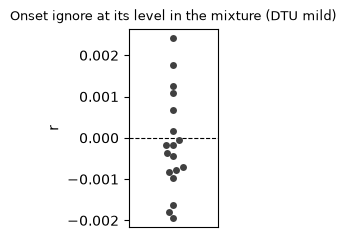

In [71]:
p = show_subject_swarm(diff, 'Onset ignore at its level in the mixture', 'DTU mild')

<small>

**Brodbeck et al. 2020: Two talkers, masked-aware vs level-aware model**

- The model that knows about the ignored speaker beats the loudness-tier model: t_max = 9.21, p < 0.001
- So the masked-onset effect is not just a response to quieter onsets

</small>

/Users/joshuaighalo/Github Repositories/cocktail-cortical/analysis/experiment.py:1063: UserWarning: Warning: converting a masked element to nan.
  mean_value = float(data.mean())


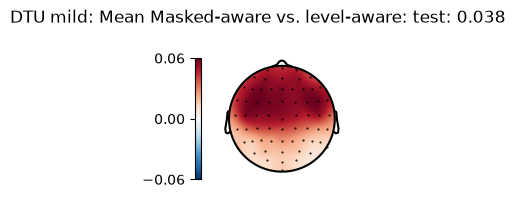

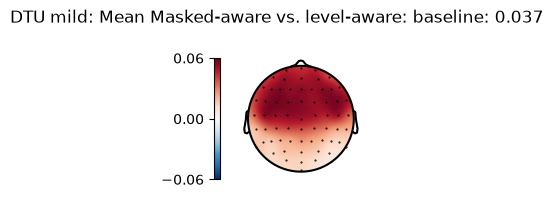

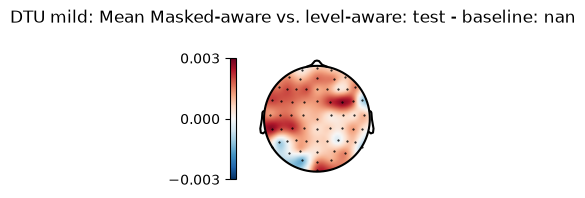

In [72]:
# Masked-aware vs. level-aware (DTU mild)
# Brodbeck et al. 2020 ran this comparison too: the ignored-speaker-aware model still beat the loudness-only model, t = 9.21, p < .001 - the masking effect isn't just about volume.
data, diff, result = dtu_model_test('Masked-aware vs. level-aware', 'mild', 'overt-masked')
show_topomap_trio(data, diff, result, 'Masked-aware vs. level-aware', 'DTU mild', None)

In [73]:
display(result)
print(f"Masked-aware vs. level-aware (DTU mild): TFCE {tfce_summary(result)}")
ttest = test.TTestOneSample(f'roi_{METRIC}', data=diff, tail=1)
print(f"Masked-aware vs. level-aware (DTU mild): ROI model comparison t({ttest.df}) = {ttest.t:.3f}, p = {ttest.p:.4f}")

<TTestRelated 'r', 'model', 'test', 'baseline', 'subject' (n=18), tail=1, samples=10000, tfce=True, p = .056>

Masked-aware vs. level-aware (DTU mild): TFCE t_max = 2.78, p = 0.056
Masked-aware vs. level-aware (DTU mild): ROI model comparison t(17) = 1.826, p = 0.0428


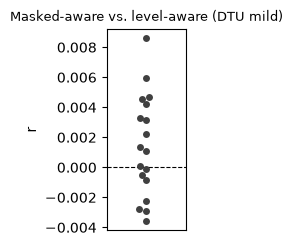

In [74]:
p = show_subject_swarm(diff, 'Masked-aware vs. level-aware', 'DTU mild')